# Tutorial 4: Integrated IPCC Risk Assessment (Risk = H x E x V)

Synthesizing multi-hazard risk and evaluating administrative hotspot priorities using inundation_risk.risk_ipcc.

## 1. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from inundation_risk.risk_ipcc import compute_ahp_weights, verify_ahp_consistency, compute_ipcc_risk, classify_risk_levels

## 2. AHP Multi-Criteria Weights

In [2]:
matrix = np.array([
    [1.0, 2.0, 4.0],
    [0.5, 1.0, 3.0],
    [0.25, 0.3333, 1.0]
])
weights, lmax, cr = compute_ahp_weights(matrix, ['Hazard', 'Exposure', 'Vulnerability'])
print('AHP Weights:', weights)
print(f'Consistency Ratio (CR): {cr:.4f} (Valid: {verify_ahp_consistency(cr)})')

AHP Weights: {'Hazard': 0.5571, 'Exposure': 0.3202, 'Vulnerability': 0.1226}
Consistency Ratio (CR): 0.0158 (Valid: True)


## 3. Risk Synthesis and Classification

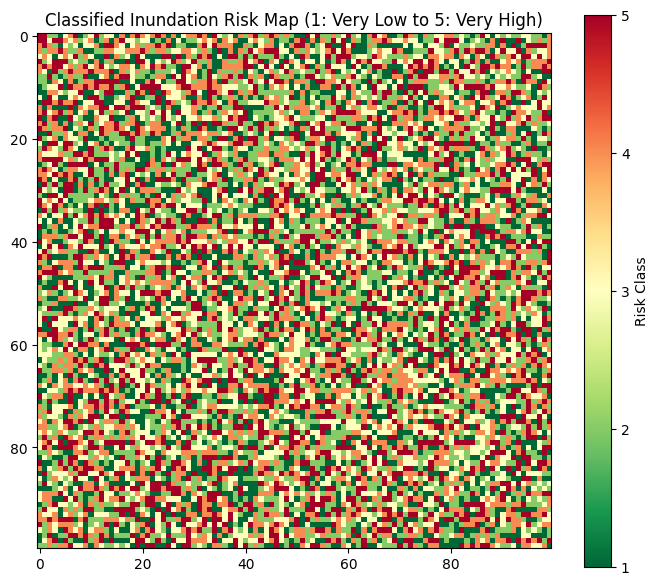

In [3]:
# Synthetic hazard, exposure, and vulnerability layers
rng = np.random.default_rng(42)
H = rng.uniform(0.1, 0.9, size=(100, 100))
E = rng.uniform(0.2, 0.8, size=(100, 100))
V = rng.uniform(0.3, 0.7, size=(100, 100))

risk = compute_ipcc_risk(H, E, V)
risk_class, thresholds = classify_risk_levels(risk, n_classes=5)

plt.figure(figsize=(7, 6))
plt.imshow(risk_class, cmap='RdYlGn_r')
plt.title('Classified Inundation Risk Map (1: Very Low to 5: Very High)')
plt.colorbar(ticks=[1, 2, 3, 4, 5], label='Risk Class')
plt.tight_layout()
plt.show()